# Part 4. Summary: the results in one place

**Project question.** For traffic-operations staff: an expressway link is moving normally now. Will it be unusually
slow 15 minutes later?

This notebook collects the results of Parts 1 to 3 and draws the tables and figures of the report. It fits no model.
**It does not read the test week.** The test-week numbers come from the saved tables of the single frozen run of
26 Nov (`results/tables/10_test.json`, `10_test.md`, `11_diagnostics.md`, written by `modelling/10_test.py` and
`modelling/11_diagnostics.py`).

| Section | What it shows | Read from |
|---|---|---|
| 1 | the design in brief | `modelling/settings.py`, `results/freeze.json` |
| 2 | the main result on the test week (report Table 1, Figure 2) | `10_test.json` |
| 3 | does it hold up? by test day, on roads never trained on, validation against test | `10_test.md`, `16_classifiers_and_roc.json` |
| 4 | the result in use: alerts, warnings ahead, calibration | `10_test.json`, `10_test.md` |
| 5 | what drives the result: inputs left out, ranking of the inputs | `10_test.json`, `06_random_forest.json`, `15_tree_and_importance.json` |
| 6 | where it works and where it fails (report Figure 3, Table 2) | `11_diagnostics.md`, the validation scores of Part 3 |
| 7 | secondary analyses fixed in advance: other horizons, 1 km segments | `10_test.json` |
| 8 | the course's other tools, as checks | `14_`, `15_`, `16_*.json` |
| 9 | the checks behind the result | `13_leakage_checks.json`, `freeze.json`, `TEST_OPENED.log`, `dry_10_test.json` |
| 10 | the answer and its limits | |
| 11 | where each requirement of the project brief is met | |

To run: open this notebook from the `notebooks/` folder with the project's Python environment (under a minute). It
writes two of the report's figures (`figures/report/report_fig2_test_week.png`, `figures/report/report_fig3_onsets_caught.png`;
the first one is made in Part 2), `figures/notebooks/part4_alerts.png` and `results/tables/part4_by_kind.json`. The figures are
drawn at the size they have on the page of the report.

*AI use: code and text drafted with Claude (Anthropic) on 28 Nov 2026. Every number below is read from a saved result
file or computed here; the cells assert that the files agree with each other where they overlap.*

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

HERE = Path.cwd()                 # notebooks/
ROOT = HERE.parent                # the project folder
sys.path.insert(0, str(ROOT / "modelling"))
import settings as S              # dates and file locations of the modelling pipeline

FIG = ROOT / "figures" / "notebooks"      # the figures this notebook draws
REPORT_FIG = ROOT / "figures" / "report"   # the figures used in the report
PIPE_FIG = ROOT / "figures" / "pipeline"   # the figures drawn by the scripts in modelling/
for folder in (FIG, REPORT_FIG):
    folder.mkdir(parents=True, exist_ok=True)
TAB = S.TABLES

def load(name):
    return json.loads((TAB / name).read_text())

def mdtable(rows, header):
    """Show a small table as Markdown."""
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

def md_tables(name):
    """The tables of a saved Markdown result file: {heading above the table: [(header, rows), ...]}."""
    out, head, cur = {}, None, None
    for line in (TAB / name).read_text().splitlines():
        if line.startswith("#"):
            head, cur = line.lstrip("#").strip(), None
        elif line.startswith("|"):
            if set(line) <= set("|-: "):
                continue
            cell = [c.strip() for c in line.strip().strip("|").split("|")]
            if cur is None:
                cur = (cell, [])
                out.setdefault(head, []).append(cur)
            else:
                cur[1].append(cell)
        else:
            cur = None
    return out

def table_under(tables, start, first_column):
    """The table whose heading starts with `start` and whose first column is called `first_column`."""
    hit = [t for h, ts in tables.items() if h.startswith(start) for t in ts if t[0][0] == first_column]
    assert len(hit) == 1, (start, first_column, len(hit))
    return hit[0]

def pct(text):
    return float(text.rstrip("%")) / 100

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#ffffff"   # white: the figures go on the report page
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight", "font.size": 9,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
                     "axes.edgecolor": "#c3c2b7", "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.labelcolor": INK2, "text.color": INK})
def save(fig, name):
    fig.savefig((REPORT_FIG if name.startswith("report_") else FIG) / name)
    plt.show()

def saved_figure(name, width=640):
    """Show a figure that an earlier script saved (nothing is drawn or computed here)."""
    display(Image(filename=str(PIPE_FIG / name), width=width))

# one colour per score in every figure (the colour follows the score, never its rank)
ORDER = ("B1", "B2", "B2p", "Lasso", "RF")
LABEL = {"B1": "B1 time-of-week rate", "B2": "B2 last observation", "B2p": "band persistence (reference)",
         "Lasso": "M1 lasso", "RF": "M2 random forest"}
SHORT = {"B1": "B1\ntime of week", "B2": "B2\nlast observation", "B2p": "band persistence\n(reference)",
         "Lasso": "M1\nlasso", "RF": "M2\nrandom forest"}
COLOR = {"B1": MUTED, "B2": INK2, "B2p": SLOT[2], "Lasso": SLOT[1], "RF": SLOT[0]}

T = load("10_test.json")                         # the single frozen run on the test week (26 Nov)
TMD = md_tables("10_test.md")                    # the same run, the tables that are not in the JSON file
DIAG = md_tables("11_diagnostics.md")            # caught and missed onsets
V = load("16_classifiers_and_roc.json")          # validation week: every score, ROC, confusion matrices
freeze = json.loads(S.FREEZE.read_text())
print(f"settings frozen at {freeze['frozen_at']}; final model {freeze['final_model']}; "
      f"alert share {freeze['operating_share']:.0%}; {len(freeze['files_sha256'])} file hashes recorded")
print(f"test week {S.TEST_DAYS[0]:%a %d %b} - {S.TEST_DAYS[1]:%a %d %b %Y}: saved result of {len(T)} analyses")

settings frozen at 2026-11-25T23:46:25+08:00; final model RF; alert share 2%; 23 file hashes recorded
test week Mon 16 Nov - Fri 20 Nov 2026: saved result of 28 analyses


## 1. The design in brief

| | |
|---|---|
| **Unit** | one expressway link (about 140 m, one direction) at one 5-minute update, 06:00-22:00, Monday to Friday without public holidays; 2,598 links |
| **Normal level** | the link's median speed band in that 15-minute slot over the 16 training weekdays (fixed from the training days) |
| **Unusual (U)** | at least 2 bands (about 20 km/h) below the normal level, now and 5 minutes ago |
| **Outcome (y)** | U 15 minutes later. Scored rows: the link is normal now (U = False) |
| **Split by time** | train 16 Oct - 6 Nov (16 weekdays), validation 10 - 13 Nov (4), test 16 - 20 Nov (5) |
| **Split by place** | AYE and CTE (689 links) are never used to fit, tune or calibrate: the transfer check |
| **Baselines** | B1 time-of-week rate (each link's past onset rate in that slot, shrunk to the slot's rate); B2 last observation (the link's drop now) |
| **Models** | M1 lasso logistic regression; M2 random forest. 96 inputs: the build's 53 and three engineered groups (Part 2) |
| **Tuning** | forward validation by windows inside the training days: fit on earlier days, check on later days |
| **Main metric** | PR-AUC on the scored rows (a score that only guesses reaches the onset rate) |
| **Also reported** | precision and recall among the top 0.5%, 1% and 2% of links at each update; episodes warned 10-15 minutes ahead |
| **Uncertainty** | 95% intervals from resampling whole days (2,000 draws), paired for differences |
| **Freeze** | every setting and the hash of every model file were written to `results/freeze.json` before the test week was opened |

"Band persistence" is a reference score we found during the analysis, not one of the two baselines fixed in advance:
the drop the link would have 10 and 15 minutes from now if its band stayed the same (the normal level of a future
slot is known in advance). It is shown because it is the strongest simple rule we know.

## 2. The main result: the test week (report Table 1 and Figure 2)

Mon 16 - Fri 20 Nov, scored once with the frozen settings.

In [2]:
m = T["main|RF"]
print(f"training roads: {m['rows']:,} rows that are normal now, {m['onsets']:,} onsets, onset rate {m['base_rate']:.4f}")
print(f"AYE + CTE (never trained on): {T['transfer|RF']['rows']:,} rows, {T['transfer|RF']['onsets']:,} onsets, "
      f"onset rate {T['transfer|RF']['base_rate']:.4f}")
rows = []
for n in ORDER:
    r, tr = T[f"main|{n}"], T[f"transfer|{n}"]
    p2, r2 = r["at_share"]["0.02"]
    rows.append([LABEL[n], f"{r['pr_auc']:.3f} ({r['ci'][0]:.3f}-{r['ci'][1]:.3f})",
                 "" if n == "B2" else ("{:+.3f}".format(r["minus_B2"]) if n == "B1" else
                                       "{:+.3f} ({:+.3f} to {:+.3f})".format(r["minus_B2"], *r["minus_B2_ci"])),
                 f"{p2:.3f} / {r2:.3f}", f"{r['event']['warned']:.1%}",
                 f"{tr['pr_auc']:.3f} ({tr['ci'][0]:.3f}-{tr['ci'][1]:.3f})"])
mdtable(rows, ["score", "PR-AUC (95% interval)", "minus B2 (paired 95%)", "precision / recall at 2%",
               "episodes warned 10-15 min ahead", "PR-AUC on AYE + CTE (95% interval)"])
print("M2 minus M1: {:+.3f} (paired 95% {:+.3f} to {:+.3f})".format(m["minus_Lasso"], *m["minus_Lasso_ci"]))
print("M2 / B2: {:.2f} times; M1 / B2: {:.2f} times; M2 / band persistence: {:.2f} times".format(
    m["pr_auc"] / T["main|B2"]["pr_auc"], T["main|Lasso"]["pr_auc"] / T["main|B2"]["pr_auc"],
    m["pr_auc"] / T["main|B2p"]["pr_auc"]))
assert abs(T["horizon15"]["RF"] - m["pr_auc"]) < 1e-12 and abs(T["horizon15"]["B2"] - T["main|B2"]["pr_auc"]) < 1e-12

training roads: 1,636,522 rows that are normal now, 20,499 onsets, onset rate 0.0125
AYE + CTE (never trained on): 596,159 rows, 7,086 onsets, onset rate 0.0119


| score | PR-AUC (95% interval) | minus B2 (paired 95%) | precision / recall at 2% | episodes warned 10-15 min ahead | PR-AUC on AYE + CTE (95% interval) |
|---|---|---|---|---|---|
| B1 time-of-week rate | 0.081 (0.064-0.100) | -0.083 | 0.084 / 0.135 | 15.8% | 0.025 (0.015-0.045) |
| B2 last observation | 0.164 (0.152-0.176) |  | 0.145 / 0.234 | 8.8% | 0.162 (0.123-0.188) |
| band persistence (reference) | 0.206 (0.191-0.220) | +0.042 (+0.037 to +0.047) | 0.175 / 0.284 | 15.9% | 0.207 (0.169-0.242) |
| M1 lasso | 0.370 (0.351-0.395) | +0.206 (+0.188 to +0.225) | 0.223 / 0.360 | 30.6% | 0.326 (0.264-0.368) |
| M2 random forest | 0.390 (0.378-0.409) | +0.226 (+0.212 to +0.241) | 0.235 / 0.381 | 31.5% | 0.367 (0.304-0.404) |

M2 minus M1: +0.020 (paired 95% +0.012 to +0.027)
M2 / B2: 2.37 times; M1 / B2: 2.25 times; M2 / band persistence: 1.89 times


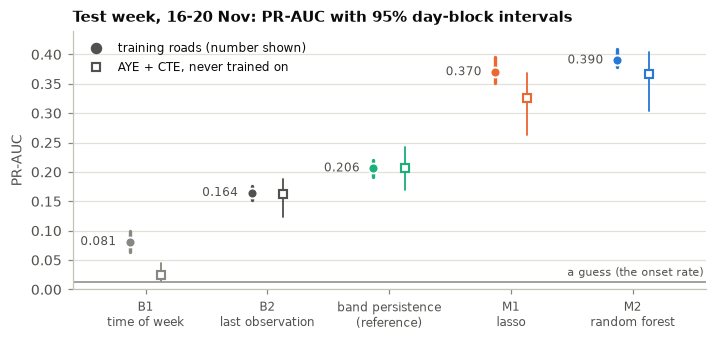

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.0), layout="constrained")
for i, n in enumerate(ORDER):
    r, tr = T[f"main|{n}"], T[f"transfer|{n}"]
    ax.plot([i - 0.13] * 2, r["ci"], color=COLOR[n], linewidth=2.2, solid_capstyle="round")
    ax.plot(i - 0.13, r["pr_auc"], marker="o", markersize=6.5, color=COLOR[n], markeredgecolor=SURFACE,
            markeredgewidth=1.2, linestyle="none")
    ax.plot([i + 0.13] * 2, tr["ci"], color=COLOR[n], linewidth=1.2, solid_capstyle="round")
    ax.plot(i + 0.13, tr["pr_auc"], marker="s", markersize=5.5, markerfacecolor=SURFACE, markeredgecolor=COLOR[n],
            markeredgewidth=1.4, linestyle="none")
    ax.text(i - 0.24, r["pr_auc"], f"{r['pr_auc']:.3f}", ha="right", va="center", fontsize=8, color=INK2)
ax.axhline(m["base_rate"], color=MUTED, linewidth=1)
ax.text(len(ORDER) - 0.42, m["base_rate"] + 0.006, "a guess (the onset rate)", ha="right", va="bottom", fontsize=7.5, color=INK2)
ax.plot([], [], marker="o", markersize=6.5, color=INK2, linestyle="none", label="training roads (number shown)")
ax.plot([], [], marker="s", markersize=5.5, markerfacecolor=SURFACE, markeredgecolor=INK2, markeredgewidth=1.4,
        linestyle="none", label="AYE + CTE, never trained on")
ax.legend(loc="upper left", fontsize=8)
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([SHORT[n] for n in ORDER], fontsize=8)
ax.set_xlim(-0.6, len(ORDER) - 0.4)
ax.set_ylim(0, 0.44)
ax.set_ylabel("PR-AUC")
ax.grid(axis="x", visible=False)
ax.set_title("Test week, 16-20 Nov: PR-AUC with 95% day-block intervals")
save(fig, "report_fig2_test_week.png")

What the table and the figure say:

- **Both models clearly beat both baselines.** The forest's PR-AUC is about 2.4 times that of last observation (B2),
  the better baseline, and the paired interval of the difference is far from zero.
- **The forest is a little ahead of the lasso**; the paired interval of the difference does not include zero.
- **The result transfers** to AYE and CTE, two expressways that were never used to fit, tune or calibrate. The
  time-of-week rate (B1) cannot transfer: it has no history for those links.
- The models are also well above band persistence, the strongest simple rule we know.

## 3. Does it hold up?

**By test day** (training roads, PR-AUC): the order of the scores is the same on each of the five days.

In [4]:
h, rows = table_under(TMD, "By day", "day")
mdtable(rows, h)
col = {name: i for i, name in enumerate(h)}
rf_days = [float(r[col[LABEL["RF"]]]) for r in rows]
b2_days = [float(r[col[LABEL["B2"]]]) for r in rows]
la_days = [float(r[col[LABEL["Lasso"]]]) for r in rows]
print(f"forest by day: {min(rf_days):.3f} to {max(rf_days):.3f}; B2 by day: {min(b2_days):.3f} to {max(b2_days):.3f}; "
      f"days on which the forest beats the lasso: {sum(a > b for a, b in zip(rf_days, la_days))} of {len(rows)}; "
      f"days on which the lasso beats B2: {sum(a > b for a, b in zip(la_days, b2_days))} of {len(rows)}")

| day | rows | base rate | B1 time-of-week rate | B2 last observation | band persistence (reference) | M1 lasso | M2 random forest |
|---|---|---|---|---|---|---|---|
| Mon 16 Nov | 319,932 | 0.0202 | 0.1026 | 0.1756 | 0.2127 | 0.3554 | 0.3781 |
| Tue 17 Nov | 324,930 | 0.0134 | 0.1070 | 0.1499 | 0.1962 | 0.3576 | 0.3793 |
| Wed 18 Nov | 326,223 | 0.0123 | 0.0955 | 0.1746 | 0.2240 | 0.4094 | 0.4231 |
| Thu 19 Nov | 331,872 | 0.0082 | 0.0582 | 0.1442 | 0.1787 | 0.3465 | 0.3829 |
| Fri 20 Nov | 333,565 | 0.0088 | 0.0570 | 0.1809 | 0.2252 | 0.3966 | 0.4011 |

forest by day: 0.378 to 0.423; B2 by day: 0.144 to 0.181; days on which the forest beats the lasso: 5 of 5; days on which the lasso beats B2: 5 of 5


**Validation week against test week.** The validation week (10-13 Nov) chose the final model and the alert share;
the test week was not used for any choice. If the choices were overfitted to the validation week, the test week would
be clearly worse. It is not.

In [5]:
key = {"B1": "B1 time-of-week rate", "B2": "B2 last observation", "Lasso": "M1 lasso", "RF": "M2 random forest"}
rows = [[LABEL[n], f"{V['perf'][key[n]]['pr_auc']:.3f}", f"{T[f'main|{n}']['pr_auc']:.3f}",
         f"{V['perf'][key[n]]['prec']:.3f} / {V['perf'][key[n]]['sens']:.3f}",
         "{:.3f} / {:.3f}".format(*T[f"main|{n}"]["at_share"]["0.02"])] for n in ("B1", "B2", "Lasso", "RF")]
mdtable(rows, ["score", "PR-AUC, validation week", "PR-AUC, test week", "precision / recall at 2%, validation",
               "precision / recall at 2%, test"])
print(f"onset rate: validation {V['perf'][key['RF']]['tp'] + V['perf'][key['RF']]['fn']:,} onsets in "
      f"{sum(V['perf'][key['RF']][k] for k in ('tp', 'fp', 'fn', 'tn')):,} rows; test {m['onsets']:,} in {m['rows']:,}")

| score | PR-AUC, validation week | PR-AUC, test week | precision / recall at 2%, validation | precision / recall at 2%, test |
|---|---|---|---|---|
| B1 time-of-week rate | 0.069 | 0.081 | 0.079 / 0.137 | 0.084 / 0.135 |
| B2 last observation | 0.128 | 0.164 | 0.138 / 0.237 | 0.145 / 0.234 |
| M1 lasso | 0.322 | 0.370 | 0.220 / 0.379 | 0.223 / 0.360 |
| M2 random forest | 0.348 | 0.390 | 0.225 / 0.389 | 0.235 / 0.381 |

onset rate: validation 13,883 onsets in 1,178,466 rows; test 20,499 in 1,636,522


## 4. The result in use

Staff can only look at a few links at a time. At each update the links are ranked by the score and the top share is
alerted. The alert share of 2% was set on the validation week (best F1 of the final model).

In [6]:
rows = []
for n in ORDER:
    r = T[f"main|{n}"]
    rows.append([LABEL[n]] + ["{:.3f} / {:.3f}".format(*r["at_share"][s]) for s in ("0.005", "0.01", "0.02")]
                + [f"{r['event']['warned']:.1%}", f"{r['event']['false_alarms_per_hour']:.0f}"])
mdtable(rows, ["score", "precision / recall, top 0.5%", "top 1%", "top 2% (the alert share)",
               "episodes warned 10-15 min ahead", "false alarms per hour (1,909 links)"])
h, fa = table_under(DIAG, "B. Failure cases, test week", "situation at t")
n_false = sum(int(r[1].replace(",", "")) for r in fa)
p2, r2 = m["at_share"]["0.02"]
n_updates = 5 * 192                 # 5 test days x 192 updates (06:00-21:55)
per_update = {s: r * m["onsets"] / p / n_updates for s, (p, r) in m["at_share"].items()}   # alerts = caught onsets / precision
n_alerts = per_update["0.02"] * n_updates
assert abs(n_alerts - n_false / (1 - p2)) < 1, (n_alerts, n_false / (1 - p2))
print(f"forest at 2%: {n_alerts:,.0f} alerts in the week, {n_false:,} of them false ({n_false / n_alerts:.1%}); "
      f"alerts per update: {per_update['0.005']:.1f} at 0.5%, {per_update['0.01']:.1f} at 1%, {per_update['0.02']:.1f} at 2% "
      f"(of {m['rows'] / n_updates:,.0f} scored links per update on average)")
print(f"episodes in the test week: {m['event']['episodes']:,}")
h, rows = table_under(TMD, "Calibration on the test week", "model")
mdtable(rows, h)

| score | precision / recall, top 0.5% | top 1% | top 2% (the alert share) | episodes warned 10-15 min ahead | false alarms per hour (1,909 links) |
|---|---|---|---|---|---|
| B1 time-of-week rate | 0.121 / 0.051 | 0.101 / 0.083 | 0.084 / 0.135 | 15.8% | 380 |
| B2 last observation | 0.270 / 0.115 | 0.207 / 0.169 | 0.145 / 0.234 | 8.8% | 355 |
| band persistence (reference) | 0.314 / 0.134 | 0.245 / 0.201 | 0.175 / 0.284 | 15.9% | 342 |
| M1 lasso | 0.368 / 0.157 | 0.298 / 0.244 | 0.223 / 0.360 | 30.6% | 322 |
| M2 random forest | 0.385 / 0.163 | 0.313 / 0.257 | 0.235 / 0.381 | 31.5% | 317 |

forest at 2%: 33,174 alerts in the week, 25,370 of them false (76.5%); alerts per update: 9.1 at 0.5%, 17.5 at 1%, 34.6 at 2% (of 1,705 scored links per update on average)
episodes in the test week: 9,763


| model | mean predicted | observed | Brier | Brier of the true base rate (hindsight) |
|---|---|---|---|---|
| B1 time-of-week rate | 0.0120 | 0.0125 | 0.01195 | 0.01237 |
| M1 lasso | 0.0115 | 0.0125 | 0.00964 | 0.01237 |
| M2 random forest | 0.0112 | 0.0125 | 0.00936 | 0.01237 |

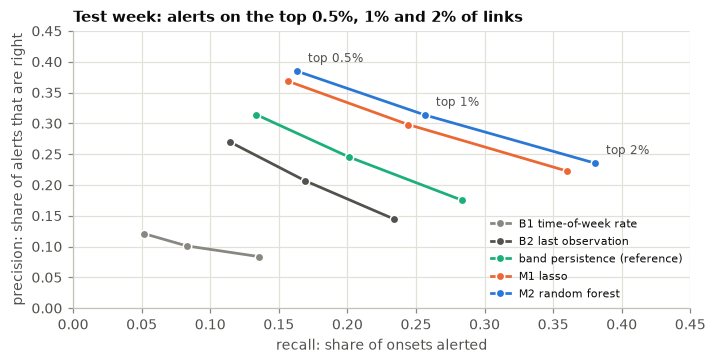

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.2), layout="constrained")
for n in ORDER:
    pr = [T[f"main|{n}"]["at_share"][s] for s in ("0.005", "0.01", "0.02")]
    ax.plot([r for p, r in pr], [p for p, r in pr], color=COLOR[n], linewidth=1.8, marker="o", markersize=5.5,
            markeredgecolor=SURFACE, markeredgewidth=1, label=LABEL[n])
for s, (p, r) in zip(("0.5%", "1%", "2%"), [m["at_share"][k] for k in ("0.005", "0.01", "0.02")]):
    ax.annotate(f"top {s}", (r, p), textcoords="offset points", xytext=(7, 6), fontsize=8, color=INK2)
ax.set_xlabel("recall: share of onsets alerted")
ax.set_ylabel("precision: share of alerts that are right")
ax.set_xlim(0, 0.45)
ax.set_ylim(0, 0.45)
ax.legend(loc="lower right", fontsize=7.5, handlelength=1.6, borderaxespad=0.3)
ax.set_title("Test week: alerts on the top 0.5%, 1% and 2% of links")
save(fig, "part4_alerts.png")

The calibration of the frozen probability maps on the test week, as drawn by `modelling/12_figures.py` from the saved
scores of the frozen run (the figure is shown as saved; nothing is recomputed here):

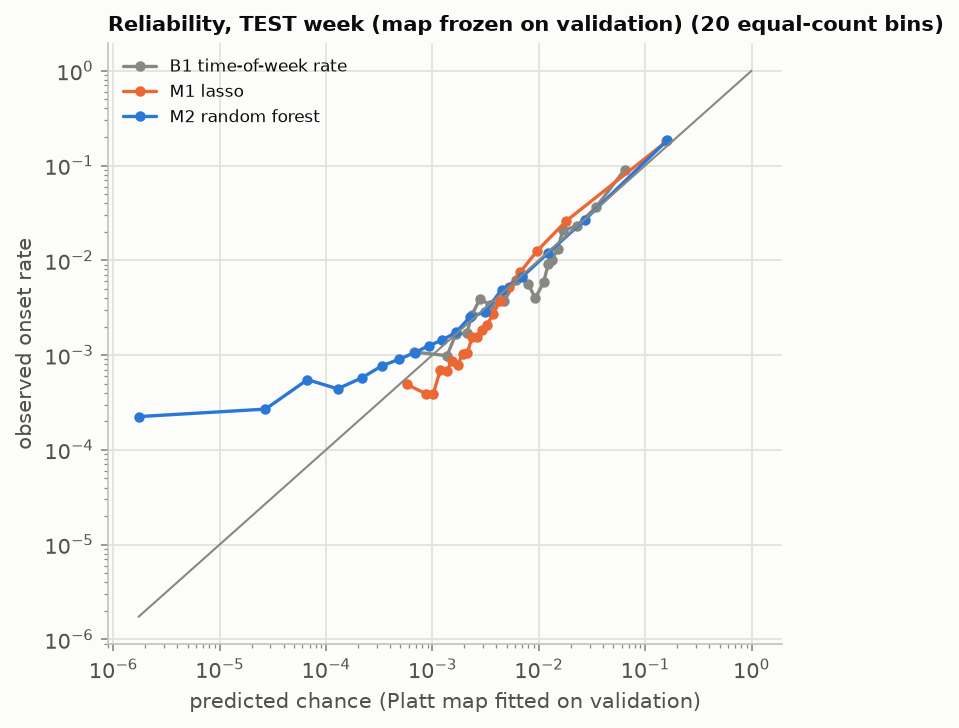

In [8]:
saved_figure("fig_test_reliability.png")

Each point is one twentieth of the rows; the grey line is perfect calibration; both axes are on a log scale. From
about 0.1% upward the predicted chances follow the observed rates. Below that the forest's chances are too low: links
to which it gives almost no chance still turn unusual a few times in 10,000. This changes neither the ranking nor the
alerts.

- At the 2% alert share about 1 alert in 4 from the forest is right, and it catches about 38% of the onsets. With a
  smaller share the alerts are more often right and catch fewer onsets. So the list is a **watch list** for staff,
  not an automatic alarm.
- The models warn of about 3 in 10 unusual episodes 10 to 15 minutes before they start; last observation warns of
  fewer than 1 in 10.
- **Calibration:** the probability maps were fitted on the validation week and frozen. On the test week the forest's
  mean predicted probability is close to the observed onset rate, and its Brier score is below that of the true base
  rate.

## 5. What drives the result

**Inputs left out** (test week, frozen settings; each row is a model fitted on the training days without that group).

In [9]:
names = [("all chosen inputs (M1 / M2)", None), ("without the joining roads", "no_conn"),
         ("without the neighbour inputs (next links and queues within 3 km)", "no_neighbours"),
         ("without the usual onset rate (HIST)", "no_hist"), ("the build's 53 inputs only", "base53_trainnorm")]
rows = []
for label, k in names:
    if k is None:
        v = [T["main|Lasso"]["pr_auc"], T["transfer|Lasso"]["pr_auc"], T["main|RF"]["pr_auc"], T["transfer|RF"]["pr_auc"]]
    else:
        v = [T[f"ablation|{k}|lasso"]["main"], T[f"ablation|{k}|lasso"]["transfer"],
             T[f"ablation|{k}|rf"]["main"], T[f"ablation|{k}|rf"]["transfer"]]
    rows.append([label] + [f"{x:.3f}" for x in v])
mdtable(rows, ["inputs", "lasso: training roads", "lasso: AYE + CTE", "forest: training roads", "forest: AYE + CTE"])
print("loss without the neighbour inputs: lasso {:.3f}, forest {:.3f}".format(
    T["main|Lasso"]["pr_auc"] - T["ablation|no_neighbours|lasso"]["main"],
    T["main|RF"]["pr_auc"] - T["ablation|no_neighbours|rf"]["main"]))
print("gain of the engineered inputs over the build's 53: lasso {:+.3f}, forest {:+.3f}".format(
    T["main|Lasso"]["pr_auc"] - T["ablation|base53_trainnorm|lasso"]["main"],
    T["main|RF"]["pr_auc"] - T["ablation|base53_trainnorm|rf"]["main"]))

| inputs | lasso: training roads | lasso: AYE + CTE | forest: training roads | forest: AYE + CTE |
|---|---|---|---|---|
| all chosen inputs (M1 / M2) | 0.370 | 0.326 | 0.390 | 0.367 |
| without the joining roads | 0.370 | 0.326 | 0.390 | 0.367 |
| without the neighbour inputs (next links and queues within 3 km) | 0.296 | 0.253 | 0.314 | 0.294 |
| without the usual onset rate (HIST) | 0.343 | 0.336 | 0.376 | 0.384 |
| the build's 53 inputs only | 0.251 | 0.241 | 0.276 | 0.266 |

loss without the neighbour inputs: lasso 0.074, forest 0.076
gain of the engineered inputs over the build's 53: lasso +0.119, forest +0.114


**Ranking of the inputs** (validation week). For the forest: how much the PR-AUC falls when a group of inputs is
shuffled together (permutation importance). For the lasso: the largest standardised coefficients, as odds ratios per
one standard deviation of the input.

In [10]:
RFJ = load("06_random_forest.json")
mdtable([[g, n, f"{d:.3f}"] for g, n, d in RFJ["importance"]],
        ["forest: input group", "inputs", "fall in validation PR-AUC when shuffled"])
boot = load("11_lasso_bootstrap.json")
top = sorted(zip(boot["names"], boot["coef"], boot["keep"]), key=lambda x: -abs(x[1]))[:8]
mdtable([[f"`{n}`", f"{c:+.3f}", f"{np.exp(c):.2f}", f"{k:.0%}"] for n, c, k in top],
        ["lasso: input", "coefficient per 1 SD", "odds ratio per 1 SD", "kept in the refits on resampled days"])
imp = load("15_tree_and_importance.json")
print(f"lasso: {sum(c != 0 for c in boot['coef'])} of {len(boot['coef'])} columns kept; "
      f"forest: rank correlation of impurity and permutation importance over the 96 inputs {imp['spearman']:.2f}")

| forest: input group | inputs | fall in validation PR-AUC when shuffled |
|---|---|---|
| NORM: normal level ahead | 8 | 0.127 |
| HOP: queue distance downstream | 3 | 0.061 |
| HOP: upstream rings | 16 | 0.041 |
| HIST: B1 rate | 1 | 0.038 |
| HOP: downstream rings | 15 | 0.030 |
| next links (f_up_*, f_dn_*) | 16 | 0.008 |
| time of day | 1 | 0.008 |
| own drops (f_d*) | 9 | 0.005 |
| rain | 4 | 0.003 |
| day of week | 5 | 0.001 |
| joining roads (f_conn_*) | 18 | -0.000 |

| lasso: input | coefficient per 1 SD | odds ratio per 1 SD | kept in the refits on resampled days |
|---|---|---|---|
| `x_dpers10` | +0.393 | 1.48 | 100% |
| `x_b1` | +0.363 | 1.44 | 100% |
| `fe_dn_r1_max0` | +0.299 | 1.35 | 100% |
| `fe_dn_r2_max0` | +0.244 | 1.28 | 100% |
| `fe_dn_q0` | -0.229 | 0.80 | 100% |
| `x_log_rain15` | +0.170 | 1.19 | 100% |
| `fe_up_r1_max0` | +0.168 | 1.18 | 100% |
| `x_hour06` | -0.161 | 0.85 | 100% |

lasso: 97 of 111 columns kept; forest: rank correlation of impurity and permutation importance over the 96 inputs 0.77


What the inputs are: `x_dpers10` is the drop the link would have 10 minutes from now if its band stayed the same
(from the normal level ahead); `x_b1` is the link's usual onset rate at that time of day; `fe_dn_r1_max0` and
`fe_dn_r2_max0` are the largest drops on the links up to 500 m and 500-1,500 m downstream; `fe_dn_q0` is the distance to
the nearest low link downstream (a negative coefficient: the nearer the queue, the higher the risk).

- **The neighbours matter most.** Without the neighbour inputs both models lose about 0.075; the joining roads add
  nothing.
- Both models lean on the same information: the normal level ahead, queues downstream, and the link's usual onset rate.
- On AYE and CTE the models **without** the usual onset rate do slightly better, because those roads have no onset
  history of their own.

## 6. Where it works and where it fails (report Figure 3 and Table 2)

**Caught and missed onsets on the test week** (training roads; the forest at the 2% alert share; from the saved
diagnostics of the frozen run). "Caught" = the link was alerted at the time of the prediction, 15 minutes ahead.
The groups within one block do not overlap; the blocks describe the same onsets in different ways.

In [11]:
start = "B. Failure cases, test week"
drop = {r[0]: r for r in table_under(DIAG, start, "drop now")[1]}
queue = {r[0]: r for r in table_under(DIAG, start, "queue")[1]}
inc = {r[0]: r for r in table_under(DIAG, start, "incident")[1]}
pers = {r[0]: r for r in table_under(DIAG, start, "band persistence")[1]}
overall = [l for l in (TAB / "11_diagnostics.md").read_text().split("## " + start)[1].splitlines() if "caught (alerted" in l][0]
print("test week:", overall)
SIT = [("the link is already low (one update so far)", drop["already low now (not yet 2 updates)"]),
       ("a low link within 500 m downstream", queue["low link <= 500 m downstream"]),
       ("the link is a little slower than normal", drop["a little slower than normal (0 < drop < 2)"]),
       ("the link is at or above its normal level", drop["at or above normal (drop <= 0)"]),
       ("no low link within 3 km downstream", queue["no low link within 3 km downstream"])]
mdtable([[s, r[1], r[2], r[3]] for s, r in SIT], ["situation at the time of prediction", "onsets", "share of onsets", "caught"])
mdtable([[k, r[1], r[2], r[3]] for k, r in inc.items()], ["incident reports (used only to interpret)", "onsets", "share of onsets", "caught"])
mdtable([[k, r[1], r[2], r[3]] for k, r in pers.items()], ["band persistence says unusual", "onsets", "share of onsets", "caught"])
mdtable(fa, ["false alarms of the forest, by situation", "false alarms", "share"])

test week: 20,499 onsets; caught (alerted at t, 15 min ahead): 38.1%.


| situation at the time of prediction | onsets | share of onsets | caught |
|---|---|---|---|
| the link is already low (one update so far) | 5,317 | 25.9% | 73.9% |
| a low link within 500 m downstream | 10,177 | 49.6% | 54.8% |
| the link is a little slower than normal | 8,345 | 40.7% | 32.7% |
| the link is at or above its normal level | 6,837 | 33.4% | 16.8% |
| no low link within 3 km downstream | 6,641 | 32.4% | 24.2% |

| incident reports (used only to interpret) | onsets | share of onsets | caught |
|---|---|---|---|
| no incident within 1 km | 12,638 | 61.7% | 34.3% |
| incident already listed at t (within 1 km) | 5,549 | 27.1% | 47.6% |
| incident starts inside the 15-min window | 2,312 | 11.3% | 36.0% |

| band persistence says unusual | onsets | share of onsets | caught |
|---|---|---|---|
| no: a new slowdown | 13,542 | 66.1% | 18.5% |
| yes: the usual level rises ahead while the band is already low | 6,957 | 33.9% | 76.1% |

| false alarms of the forest, by situation | false alarms | share |
|---|---|---|
| other | 9,883 | 39.0% |
| queue <= 500 m downstream did not arrive | 9,493 | 37.4% |
| low now, recovered within 15 min | 4,478 | 17.7% |
| normal level rises ahead (band persistence says low) | 1,516 | 6.0% |

**By kind of onset, validation week.** Every row that is normal now is put in one of three groups using only what is
known at the time of the prediction (Part 2, section 8): A the slowdown is already forming on the link, B a queue is
just ahead, C neither. The alerts are the same as above (the top 2% of links at each update, over all rows).

In [12]:
scores = S.PREDS / "part3_validation_scores.parquet"      # written by the Part 3 notebook
saved = TAB / "part4_by_kind.json"
if scores.exists():
    import common as C                                     # the pipeline's own alert rule and PR-AUC
    vs = pl.read_parquet(scores)
    assert vs.select("LinkID", "t").equals(vs.select("LinkID", "t").sort("LinkID", "t")), "rows must be in (LinkID, t) order"
    y, t = vs["y"].to_numpy(), vs["t"].to_numpy()
    col = {"B1": "b1", "B2": "b2", "Lasso": "lasso", "RF": "rf_raw"}
    alerts = {n: C.alerts_at_share(t, vs[c].to_numpy(), freeze["operating_share"]) for n, c in col.items()}
    # the same alerts as the saved validation table (confusion matrix of the forest)
    assert int((alerts["RF"] & y).sum()) == V["perf"]["M2 random forest"]["tp"]
    assert int((alerts["RF"] & ~y).sum()) == V["perf"]["M2 random forest"]["fp"]
    kind = {}
    for g in ("A forming here", "B queue ahead", "C new"):
        k = (vs["group"] == g).to_numpy()
        kind[g] = {"share_rows": float(k.mean()), "share_onsets": float(y[k].sum() / y.sum()), "onset_rate": float(y[k].mean()),
                   "scores": {n: {"pr_auc": C.ap(y[k], vs[c].to_numpy()[k]),
                                  "recall": float((alerts[n] & y & k).sum() / max(1, (y & k).sum())),
                                  "precision": float((alerts[n] & y & k).sum() / max(1, (alerts[n] & k).sum()))}
                              for n, c in col.items()}}
    saved.write_text(json.dumps(kind, indent=1))
else:
    print("the validation scores of Part 3 are not here (run Part 3 first); showing the saved table")
    kind = json.loads(saved.read_text())
rows = []
for g, d in kind.items():
    for n in ("B1", "B2", "Lasso", "RF"):
        s = d["scores"][n]
        rows.append([g if n == "B1" else "", f"{d['share_rows']:.1%}" if n == "B1" else "",
                     f"{d['share_onsets']:.1%}" if n == "B1" else "", f"{d['onset_rate']:.4f}" if n == "B1" else "",
                     LABEL[n], f"{s['pr_auc']:.3f}", f"{s['recall']:.1%}", f"{s['precision']:.3f}"])
mdtable(rows, ["group", "share of rows", "share of onsets", "onset rate", "score", "PR-AUC in the group",
               "caught at 2%", "precision"])

| group | share of rows | share of onsets | onset rate | score | PR-AUC in the group | caught at 2% | precision |
|---|---|---|---|---|---|---|---|
| A forming here | 13.2% | 67.5% | 0.0601 | B1 time-of-week rate | 0.200 | 15.1% | 0.260 |
|  |  |  |  | B2 last observation | 0.186 | 35.2% | 0.138 |
|  |  |  |  | M1 lasso | 0.415 | 49.6% | 0.285 |
|  |  |  |  | M2 random forest | 0.446 | 51.2% | 0.278 |
| B queue ahead | 2.1% | 10.7% | 0.0594 | B1 time-of-week rate | 0.119 | 8.2% | 0.131 |
|  |  |  |  | B2 last observation | 0.061 | 0.0% | 0.000 |
|  |  |  |  | M1 lasso | 0.227 | 33.3% | 0.127 |
|  |  |  |  | M2 random forest | 0.240 | 34.8% | 0.157 |
| C new | 84.7% | 21.8% | 0.0030 | B1 time-of-week rate | 0.018 | 12.1% | 0.021 |
|  |  |  |  | B2 last observation | 0.003 | 0.0% | 0.000 |
|  |  |  |  | M1 lasso | 0.044 | 4.3% | 0.034 |
|  |  |  |  | M2 random forest | 0.053 | 2.7% | 0.024 |

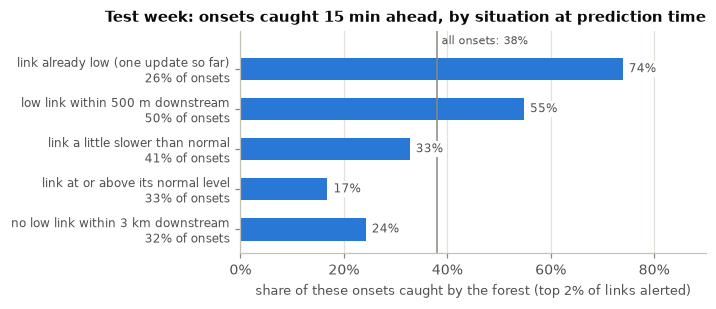

In [13]:
caught = [pct(r[3]) for s, r in SIT]
share = [pct(r[2]) for s, r in SIT]
allc = float(overall.split("ahead): ")[1].rstrip(".%")) / 100
fig, ax = plt.subplots(figsize=(6.4, 2.7), layout="constrained")
ypos = np.arange(len(SIT))[::-1]
ax.barh(ypos, caught, height=0.56, color=SLOT[0])
for yy, c in zip(ypos, caught):
    ax.text(c + 0.012, yy, f"{c:.0%}", va="center", fontsize=8, color=INK2, zorder=3,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.2))
ax.axvline(allc, color=MUTED, linewidth=1, zorder=1)
ax.text(allc + 0.008, len(SIT) - 0.45, f"all onsets: {allc:.0%}", fontsize=7.5, color=INK2, va="bottom")
ax.set_yticks(ypos)
short = ["link already low (one update so far)", "low link within 500 m downstream", "link a little slower than normal",
         "link at or above its normal level", "no low link within 3 km downstream"]
assert len(short) == len(SIT)
ax.set_yticklabels([f"{s}\n{sh:.0%} of onsets" for s, sh in zip(short, share)], fontsize=8)
ax.set_xlim(0, 0.9)
ax.set_ylim(-0.6, len(SIT) - 0.05)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8])
ax.set_xticklabels(["0%", "20%", "40%", "60%", "80%"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of these onsets caught by the forest (top 2% of links alerted)", fontsize=8.5)
ax.set_title("Test week: onsets caught 15 min ahead, by situation at prediction time", loc="right")
save(fig, "report_fig3_onsets_caught.png")

**Subgroups on the test week** (training roads; PR-AUC; each group has its own onset rate, so compare the scores
within a row, not the rows with each other).

In [14]:
h, rows = table_under(TMD, "Subgroups", "group")
mdtable(rows, h)
col = {name: i for i, name in enumerate(h)}
rf = {r[0]: (float(r[col[LABEL["RF"]]]), int(r[1].replace(",", "")), float(r[2])) for r in rows}
roads = {k: v for k, v in rf.items() if "Exp" in k or "Parkway" in k}
small = {k: v for k, v in rf.items() if "Flyover" in k}
lo, hi = min(roads, key=lambda k: roads[k][0]), max(roads, key=lambda k: roads[k][0])
print(f"forest by expressway ({len(roads)}): {roads[lo][0]:.3f} ({lo}) to {roads[hi][0]:.3f} ({hi})")
print("short flyovers: " + "; ".join(f"{k} {v[0]:.3f} (about {v[1] * v[2]:.0f} onsets)" for k, v in small.items()))

| group | rows | base rate | B1 time-of-week rate | B2 last observation | band persistence (reference) | M1 lasso | M2 random forest |
|---|---|---|---|---|---|---|---|
| peak (07:00-09:59, 17:00-19:59) | 601,265 | 0.0243 | 0.1007 | 0.1912 | 0.2381 | 0.4107 | 0.4280 |
| off-peak | 1,035,257 | 0.0057 | 0.0386 | 0.1251 | 0.1503 | 0.2663 | 0.2922 |
| rain in the last 30 min | 124,091 | 0.0498 | 0.1726 | 0.2054 | 0.2446 | 0.4077 | 0.4234 |
| dry | 1,512,431 | 0.0095 | 0.0705 | 0.1530 | 0.1963 | 0.3545 | 0.3758 |
| Aljunied West Flyover | 5,285 | 0.0044 | 0.0058 | 0.0181 | 0.0180 | 0.0208 | 0.0291 |
| Bukit Timah Expressway | 144,103 | 0.0150 | 0.0679 | 0.1778 | 0.2094 | 0.3497 | 0.3910 |
| East Coast Parkway | 203,020 | 0.0096 | 0.1070 | 0.1824 | 0.2302 | 0.4227 | 0.4428 |
| Kallang Bahru Flyover | 4,189 | 0.0232 | 0.0591 | 0.1402 | 0.1492 | 0.2562 | 0.2314 |
| Kallang Paya Lebar Expressway | 174,459 | 0.0071 | 0.0567 | 0.1351 | 0.2341 | 0.3083 | 0.3505 |
| Kranji Expressway | 115,390 | 0.0041 | 0.0248 | 0.0869 | 0.0933 | 0.2044 | 0.2357 |
| Marina Coastal Expressway | 67,334 | 0.0046 | 0.0796 | 0.1806 | 0.1402 | 0.3802 | 0.4315 |
| Pan Island Expressway | 564,063 | 0.0169 | 0.0824 | 0.1754 | 0.2109 | 0.3809 | 0.4006 |
| Seletar Expressway | 157,822 | 0.0155 | 0.0780 | 0.1752 | 0.1995 | 0.3700 | 0.3584 |
| Tampines Expressway | 200,857 | 0.0114 | 0.1200 | 0.1464 | 0.2272 | 0.3844 | 0.3986 |

forest by expressway (8): 0.236 (Kranji Expressway) to 0.443 (East Coast Parkway)
short flyovers: Aljunied West Flyover 0.029 (about 23 onsets); Kallang Bahru Flyover 0.231 (about 97 onsets)


The reading of this section:

- The models are good when **the slowdown has already begun to form** (the link is low at one update, or a queue is
  within 500 m downstream). Most caught onsets are of this kind.
- They are weak when **the link and the road ahead look normal** at the time of the prediction: few of these onsets
  are caught, and in the validation week the scores hardly rank them (group C).
- Onsets with an incident report that starts inside the 15-minute window are caught no better than the others.
  Incident reports are not an input, and such a slowdown has shown no sign yet.
- Performance differs by road and is lower outside the peaks, where onsets are rarer.

So the models predict **where an existing slowdown will spread or deepen** in the next 15 minutes. They rarely foresee
a slowdown that starts on a clear road. With speed bands of 10 km/h every 5 minutes and no traffic counts, the data
hold almost no early sign of those.

## 7. Secondary analyses fixed in advance (the proposal's fallback plan)

Other horizons, and 1 km segments instead of single links. Test week, frozen settings.

In [15]:
mdtable([[f"{hh} min" + (" (main)" if hh == 15 else ""), f"{T[f'horizon{hh}']['base_rate']:.4f}"]
         + [f"{T[f'horizon{hh}'][n]:.3f}" for n in ("B1", "B2", "Lasso", "RF")] for hh in (5, 10, 15, 30)],
        ["horizon", "onset rate", "B1", "B2", "M1 lasso", "M2 forest"])
mdtable([[k.split("|")[1], f"{v['rows']:,}", f"{v['base_rate']:.4f}"] + [f"{v[n]:.3f}" for n in ("B1", "B2", "Lasso", "RF")]
         for k, v in T.items() if k.startswith("segments|")],
        ["1 km segments", "rows", "onset rate", "B1", "B2", "M1 lasso", "M2 forest"])

| horizon | onset rate | B1 | B2 | M1 lasso | M2 forest |
|---|---|---|---|---|---|
| 5 min | 0.0059 | 0.041 | 0.765 | 0.863 | 0.842 |
| 10 min | 0.0099 | 0.058 | 0.276 | 0.470 | 0.491 |
| 15 min (main) | 0.0125 | 0.081 | 0.164 | 0.370 | 0.390 |
| 30 min | 0.0175 | 0.117 | 0.075 | 0.244 | 0.259 |

| 1 km segments | rows | onset rate | B1 | B2 | M1 lasso | M2 forest |
|---|---|---|---|---|---|---|
| training roads | 229,807 | 0.0072 | 0.048 | 0.280 | 0.374 | 0.362 |
| AYE + CTE | 82,020 | 0.0076 | 0.015 | 0.321 | 0.362 | 0.387 |

- **5 minutes ahead** last observation alone is already a strong score: a link that is low at one update is very
  often low at the next one, which makes it unusual. The models add less here, and the lasso is ahead of the forest.
- **The further ahead, the weaker last observation.** At 30 minutes it falls below the time-of-week rate, and the
  models keep a clear margin.
- **On 1 km segments** both models still beat last observation, by a smaller margin: on segments last observation
  is itself a much better score than on single links. On the training roads the lasso is ahead of the forest.

## 8. The course's other tools, as checks (train and validation days only)

These runs changed no frozen setting. They ask whether the choices would have been different with other tools of the
course.

**Forward validation by windows.** The frozen settings were chosen on two windows inside the training days (W2). A
finer scheme starts with 4 days and adds 2 days at a time (W6: six windows).

In [16]:
W = load("14_validation_windows.json")
print("W6 checks on:", ", ".join(W["windows"]["W6"]["check"]))
rows = [[f"x {k}", f"{W['lasso']['W2'][k]['mean']:.4f}", f"{W['lasso']['W6'][k]['mean']:.4f}", f"{W['lasso']['W6'][k]['se']:.4f}"]
        for k in W["lasso"]["W6"]]
mdtable(rows, ["lasso penalty / largest penalty", "W2 mean PR-AUC", "W6 mean PR-AUC", "W6 standard error"])
name = {"sqrt|20": "max_features = sqrt(p) (the usual forest), leaf 20", "0.35|20": "max_features 0.35, leaf 20",
        "0.6|20": "max_features 0.6, leaf 20 (frozen)", "1.0|20": "all inputs at each split (bagging), leaf 20",
        "0.35|80": "max_features 0.35, leaf 80", "0.6|80": "max_features 0.6, leaf 80"}
mdtable([[name[k], f"{W['forest']['W2'][k]['mean']:.4f}", f"{v['mean']:.4f}", f"{v['se']:.4f}"] for k, v in W["forest"]["W6"].items()],
        ["forest setting", "W2 mean PR-AUC", "W6 mean PR-AUC", "W6 standard error"])
best_l = max(W["lasso"]["W6"], key=lambda k: W["lasso"]["W6"][k]["mean"])
best_f = max(W["forest"]["W6"], key=lambda k: W["forest"]["W6"][k]["mean"])
print(f"W6 best lasso penalty x {best_l}: {W['lasso']['W6'][best_l]['mean']:.4f}; frozen x {freeze['lasso']['frac_of_lambda_max']}: "
      f"{W['lasso']['W6'][str(freeze['lasso']['frac_of_lambda_max'])]['mean']:.4f}")
print(f"W6 best forest setting {best_f}: {W['forest']['W6'][best_f]['mean']:.4f}; frozen 0.6|20: {W['forest']['W6']['0.6|20']['mean']:.4f}")

W6 checks on: 22 Oct - 23 Oct, 26 Oct - 27 Oct, 28 Oct - 29 Oct, 30 Oct - 02 Nov, 03 Nov - 04 Nov, 05 Nov - 06 Nov


| lasso penalty / largest penalty | W2 mean PR-AUC | W6 mean PR-AUC | W6 standard error |
|---|---|---|---|
| x 0.5 | 0.2297 | 0.2271 | 0.0129 |
| x 0.2 | 0.2907 | 0.2928 | 0.0200 |
| x 0.1 | 0.3166 | 0.3148 | 0.0178 |
| x 0.03 | 0.3284 | 0.3248 | 0.0177 |
| x 0.01 | 0.3434 | 0.3377 | 0.0188 |
| x 0.003 | 0.3512 | 0.3441 | 0.0195 |
| x 0.001 | 0.3527 | 0.3444 | 0.0196 |
| x 0.0003 | 0.3530 | 0.3438 | 0.0197 |
| x 0.0001 | 0.3530 | 0.3435 | 0.0197 |

| forest setting | W2 mean PR-AUC | W6 mean PR-AUC | W6 standard error |
|---|---|---|---|
| max_features = sqrt(p) (the usual forest), leaf 20 | 0.3623 | 0.3624 | 0.0185 |
| max_features 0.35, leaf 20 | 0.3712 | 0.3690 | 0.0187 |
| max_features 0.6, leaf 20 (frozen) | 0.3712 | 0.3683 | 0.0190 |
| all inputs at each split (bagging), leaf 20 | 0.3666 | 0.3607 | 0.0198 |
| max_features 0.35, leaf 80 | 0.3630 | 0.3613 | 0.0192 |
| max_features 0.6, leaf 80 | 0.3643 | 0.3615 | 0.0194 |

W6 best lasso penalty x 0.001: 0.3444; frozen x 0.0003: 0.3438
W6 best forest setting 0.35|20: 0.3690; frozen 0.6|20: 0.3683


The finer scheme gives the same picture: the frozen lasso penalty and the frozen forest setting are within 0.001 of
the best, far inside one standard error. For the forest, `max_features` 0.35 and 0.6 are within 0.001 of each other
in both schemes (in W2 they tie at 4 decimals). The written rule sends ties to the smaller value; the frozen run kept
0.6, because part of its tuning grid had been stored rounded to 4 decimals. This is a slip in the process, and it is
left as it is: the two settings score 0.3496 and 0.3482 on the validation week (Part 3, section 5), and changing the
model after the test week was opened would be worse than the tie.

**One decision tree, pruned by cost-complexity**, against the forest; **LDA and QDA**; **ridge and elastic net**
against the lasso; **ROC-AUC** beside PR-AUC. Validation week, training roads, alerts on the top 2% of links.

In [17]:
rows = [[k, f"{v['pr_auc']:.3f}", f"{v['roc_auc']:.3f}", f"{v['tp']:,}", f"{v['fp']:,}", f"{v['fn']:,}", f"{v['tn']:,}",
         f"{v['sens']:.3f}", f"{v['spec']:.4f}", f"{v['prec']:.3f}", f"{v['acc']:.4f}"] for k, v in V["perf"].items()]
mdtable(rows, ["score", "PR-AUC", "ROC-AUC", "TP", "FP", "FN", "TN", "sensitivity (recall)", "specificity", "precision", "accuracy"])
a_min = [a for a in imp["alphas"] if abs(a["alpha"] - imp["alpha_min"]) < 1e-15][0]
a_1se = [a for a in imp["alphas"] if abs(a["alpha"] - imp["alpha_1se"]) < 1e-15][0]
big = imp["alphas"][0]
print(f"unpruned tree: {big['leaves']:,} leaves, PR-AUC {big['train']:.3f} on its own rows and {big['cv']:.3f} on later days (W6)")
print(f"pruned, minimum-error rule: {a_min['leaves']} leaves, W6 mean {a_min['cv']:.3f}; one-standard-error rule: "
      f"{a_1se['leaves']} leaves, W6 mean {a_1se['cv']:.3f}")
pen = V["penalties"]
print("W6 mean PR-AUC: lasso (frozen penalty) {:.4f}; best ridge {:.4f}; best elastic net {:.4f}; LDA {:.4f}; QDA {:.4f}".format(
    W["lasso"]["W6"]["0.0003"]["mean"], max(v["mean"] for k, v in pen.items() if k.startswith("ridge")),
    max(v["mean"] for k, v in pen.items() if k.startswith("enet")), pen["lda"]["mean"], pen["qda"]["mean"]))
never = 1 - (V["perf"]["M2 random forest"]["tp"] + V["perf"]["M2 random forest"]["fn"]) / sum(V["perf"]["M2 random forest"][k] for k in ("tp", "fp", "fn", "tn"))
print(f"accuracy of never alerting: {never:.4f}")
mdtable([[c["r"], f"{c['threshold']:.3f}", f"{c['per_update']:.1f}", f"{c['sens']:.3f}", f"{c['prec']:.3f}"] for c in V["costs"]],
        ["a missed onset costs r false alarms", "alert when the probability is above 1 / (1 + r)", "alerts per update",
         "sensitivity", "precision"])

| score | PR-AUC | ROC-AUC | TP | FP | FN | TN | sensitivity (recall) | specificity | precision | accuracy |
|---|---|---|---|---|---|---|---|---|---|---|
| B1 time-of-week rate | 0.069 | 0.770 | 1,902 | 22,042 | 11,981 | 1,142,541 | 0.137 | 0.9811 | 0.079 | 0.9711 |
| B2 last observation | 0.128 | 0.771 | 3,295 | 20,649 | 10,588 | 1,143,934 | 0.237 | 0.9823 | 0.138 | 0.9735 |
| pruned tree (one-standard-error rule) | 0.258 | 0.916 | 4,998 | 18,946 | 8,885 | 1,145,637 | 0.360 | 0.9837 | 0.209 | 0.9764 |
| pruned tree (minimum-error rule) | 0.268 | 0.923 | 5,021 | 18,923 | 8,862 | 1,145,660 | 0.362 | 0.9838 | 0.210 | 0.9764 |
| LDA | 0.271 | 0.916 | 5,011 | 18,933 | 8,872 | 1,145,650 | 0.361 | 0.9837 | 0.209 | 0.9764 |
| QDA | 0.082 | 0.893 | 1,897 | 22,047 | 11,986 | 1,142,536 | 0.137 | 0.9811 | 0.079 | 0.9711 |
| M1 lasso | 0.322 | 0.927 | 5,266 | 18,678 | 8,617 | 1,145,905 | 0.379 | 0.9840 | 0.220 | 0.9768 |
| M2 random forest | 0.348 | 0.942 | 5,397 | 18,547 | 8,486 | 1,146,036 | 0.389 | 0.9841 | 0.225 | 0.9771 |

unpruned tree: 6,216 leaves, PR-AUC 0.858 on its own rows and 0.239 on later days (W6)
pruned, minimum-error rule: 83 leaves, W6 mean 0.287; one-standard-error rule: 47 leaves, W6 mean 0.280
W6 mean PR-AUC: lasso (frozen penalty) 0.3438; best ridge 0.3439; best elastic net 0.3438; LDA 0.2760; QDA 0.0782
accuracy of never alerting: 0.9882


| a missed onset costs r false alarms | alert when the probability is above 1 / (1 + r) | alerts per update | sensitivity | precision |
|---|---|---|---|---|
| 1 | 0.500 | 3.3 | 0.126 | 0.697 |
| 5 | 0.167 | 22.9 | 0.433 | 0.341 |
| 10 | 0.091 | 44.0 | 0.573 | 0.236 |
| 20 | 0.048 | 81.1 | 0.697 | 0.155 |
| 50 | 0.020 | 159.5 | 0.826 | 0.094 |

- **A single tree overfits; pruning helps; the forest is better still.** Unpruned, the tree is nearly perfect on its
  own rows and poor on later days. Pruned to 47-83 leaves it reaches about 0.26-0.27 on the validation week, against
  0.35 for the forest: this gap is what averaging 400 trees buys.
- **The kind of penalty does not matter** with 4.6 million rows and 111 columns: ridge and elastic net tie with the
  lasso. We keep the lasso because it also selects inputs.
- **LDA** is about as good as the pruned tree. **QDA** fails here: it estimates a full covariance matrix for each
  class, and our inputs are strongly correlated and far from normal.
- **ROC-AUC** ranks the models the same way as PR-AUC but hides the gap between the two baselines, and it looks high
  for every score, because it also counts the many easy "no" rows. **Accuracy** is useless here: never alerting is
  98.8% accurate.
- **Costs.** Alerting on the top 2% of links gives about as many alerts as a probability threshold for a missed onset
  that costs 5 to 10 false alarms. A team that knows its costs can choose the threshold from this table.

## 9. The checks behind the result

In [18]:
L = load("13_leakage_checks.json")
mdtable([[c[0], c[1], c[2]] for c in L["checks"]], ["#", "leakage check (train and validation days)", "result"])
res = [c[2] for c in L["checks"]]
print(f"{res.count('OK')} checks passed, {res.count('FAIL')} failed, {res.count('NOTE')} notes (measurements to read)")
c2 = {k: float(np.mean(v)) for k, v in L["C2"].items()}
print("note C2, the forest on the two tuning windows: " + "; ".join(f"{k} {v:.4f}" for k, v in c2.items()))
dry = load("dry_10_test.json")
print("dry run of the test script on the validation week: forest {:.4f}, lasso {:.4f} (validation table: {:.4f}, {:.4f})".format(
    dry["main|RF"]["pr_auc"], dry["main|Lasso"]["pr_auc"], V["perf"]["M2 random forest"]["pr_auc"], V["perf"]["M1 lasso"]["pr_auc"]))
assert abs(dry["main|RF"]["pr_auc"] - V["perf"]["M2 random forest"]["pr_auc"]) < 1e-6
assert abs(dry["main|Lasso"]["pr_auc"] - V["perf"]["M1 lasso"]["pr_auc"]) < 1e-9
print()
print(f"frozen at {freeze['frozen_at']}: {freeze['statement']}")
print("the test week was read:")
print((S.RESULTS / "TEST_OPENED.log").read_text().rstrip())

| # | leakage check (train and validation days) | result |
|---|---|---|
| A1 | each split's rows lie on its own days | OK |
| A4 | frozen model files unchanged since their freeze; every freeze before the test opening | OK |
| A4b | code files changed after the main freeze (models unaffected; for the record) | NOTE |
| B1 | NORM inputs depend only on the link and the clock time (the same on every day) | OK |
| B2 | the normal level is the median of the train weekdays' bands only | OK |
| B3 | HOP '10 min ago' inputs equal the 'now' inputs at t - 10 | OK |
| B4 | truncation test: HOP rebuilt from the rows up to a cut time equals the stored inputs | OK |
| B5 | the label looks 15 min ahead and the 1 km segment lags look back | OK |
| A2 | the forest was fitted on train-day rows only (training roads) | OK |
| A3 | the lasso was fitted on train-day rows only (training roads) | OK |
| B6 | no single input gives the answer (validation week, each input alone as a score) | OK |
| B7 | 'band persistence says low at t + 10 and t + 15' is a forecast, not the answer | NOTE |
| C1 | HIST on the fit rows leaves the own day out, so within a link x slot it is LOWER on days with onsets | NOTE |
| C2 | does the own-day trace in HIST change the fold scores? (forests on train days only) | NOTE |
| D | accuracy rewards 'always no'; PR-AUC does not, and it does not depend on a threshold | NOTE |

10 checks passed, 0 failed, 5 notes (measurements to read)
note C2, the forest on the two tuning windows: as fitted (own day left out) 0.3712; past days only (no own-day information) 0.3686; no HIST 0.3653
dry run of the test script on the validation week: forest 0.3482, lasso 0.3220 (validation table: 0.3482, 0.3220)

frozen at 2026-11-25T23:46:25+08:00: Written before any test-week (14-20 Nov) row, label or raw file was opened by this analysis.
the test week was read:
2026-11-26T01:05:16+08:00  test week opened for the frozen test run (OPEN_TEST_WEEK=yes); this run gives results/tables/10_test.md
2026-11-26T08:13:07+08:00  read-only second look: PR-AUC of the frozen forest by number of trees (nothing refitted or chosen; not a reported result)
2026-11-26T11:24:51+08:00  exploratory second look: forest refitted on the 20 train + validation days with the frozen settings and extra inputs, test days 16-20 Nov only (not a reported result)


- **Freeze.** Every setting, the calibration maps, the alert share and the SHA-256 hash of each code and model file
  were written to `results/freeze.json` before the test week was opened. `modelling/10_test.py` checks the hashes
  before it scores anything.
- **Dry run.** The test script was first run on the validation week dressed as a test week. It reproduces the
  validation numbers, so the script itself adds no error.
- **Leakage checks.** The days of the three splits never mix; the normal level uses the training days only; every
  input is known at the time of the prediction (a truncation test rebuilds the inputs from the rows up to a cut time).
- **One honest note (C1, C2).** The usual-onset-rate input leaves the row's own day out on the training rows. A
  model could in principle read a trace of the row's own answer from that. Measured on the tuning windows it is worth
  about 0.003 of PR-AUC, and validation and test rows never have it.
- **The test week was read three times,** all recorded above. Only the first run is reported. The second was a
  read-only curve; nothing was chosen from it. The third was an exploratory variant with extra inputs, fitted on
  train and validation days together; it is not our result and it changed nothing in this package.

## 10. The answer, and its limits

**Answer.** Yes, in part. Recent speed bands of a link and its neighbours, with rain and the time of day, predict an
unusual slowdown 15 minutes ahead much better than the time-of-week rate or last observation, on a week that was
never used for any choice and on two expressways that were never trained on. The gain comes mostly from two things:
what the link's usual level will be in the next minutes, and queues on the road ahead.

**What it means for operations.** The ranked list is a watch list, not an alarm: at the 2% alert share about three
alerts in four are false. The data reach us a median of 4 minutes after the update time (`DATA.md`), so "15 minutes
ahead" is about 11 minutes in practice.

**Limits.**
- The models mostly predict where an existing slowdown will spread. A slowdown that starts on a clear road is rarely
  foreseen.
- One season: weekdays from 16 Oct to 20 Nov 2026, with 16 training days. Nothing is known about other months.
- The speed bands are coarse (10 km/h; the top band is "70 km/h or more"), and the label counts dips as short as 10
  minutes.
- A link that is normally at band 1 or 2 cannot show a 2-band drop, so unusual events inside heavy everyday
  congestion are not labelled.
- These are predictions, not causes: rain and queues go together with onsets; the analysis does not show that they
  cause them.

**Next steps.** Finer inputs (speeds instead of bands, traffic counts), a longer collection period, and an alert rule
based on one probability threshold with stated costs.

## 11. Where each requirement of the project brief is met

| Requirement (brief) | Where |
|---|---|
| One primary question, with an audience (3.1) | the top of every notebook; report, section 2 |
| Data documentation: source, access date, licence, unit, rules, dictionary, checks, limits (3.2) | `DATA.md`; `docs/data_rules.md`; `docs/model_data/README.md` |
| Raw-to-final processing is scripted (3.2, 6.2) | `analysis/lta_collector.py`, `get_context_data.py`, `build_data.py`; rebuilt step by step in Part 1 |
| Exploratory analysis: distributions, missingness, dependence, class balance, subgroups (3.3) | Part 2; `03_visuals.ipynb` |
| A transparent baseline (3.3) | B1 and B2: Part 3, section 2 |
| Two approaches from different course families (3.3) | lasso logistic regression and random forest: Part 3 |
| Out-of-sample evaluation that matches the use (3.3, 4) | later days and unseen roads: sections 2 and 3 here |
| Interpretation and diagnosis: uncertainty, errors, sensitivity, failure cases (3.3) | sections 2 to 7 here; Part 3 |
| Outcome and metric fixed before comparing models (4) | `DECISIONS.md` (13 Oct); `modelling/settings.py`; `results/freeze.json` |
| Test set untouched until the plan is stable (4) | `results/freeze.json`; section 9 here |
| Preprocessing, input selection and tuning on training data only (4) | Part 3, sections 3 to 5; leakage checks, section 9 here |
| Not accuracy alone for a rare outcome (4) | PR-AUC, precision, recall: sections 2 and 4; ROC-AUC in section 8 |
| Negative results reported (4) | sections 6, 7 and 8 here (new slowdowns, the forest tie, QDA, the usual-onset-rate note) |
| AI use disclosed (5) | `AI_USE.md` |
| Reproducible package (6.2) | `README.md` |